##### Introduction to Artificial Intelligence
## Lab 11
This lab covers data preprocessing

#### Data Preprocessing, Cleaning & Feature Engineering

**Lab Outcomes**
- Inspect data structure, types, distributions and quality.
- Detect and handle missing values, duplicates, inconsistent and invalid values, and outliers.
- Apply preprocessing to numerical, categorical and temporal data.
- Understand domain-specific data checks (medical, network, HR, finance, images, text, audio, graphs and geospatial).
- Engineer features, encode categories and scale numerical features.
- Avoid data leakage using train/test splits and pipelines.
- Understand typical preprocessing requirements of major ML and DL model families.

**Group Exercise:**
Select your group member and select a dataset from Kaggle\
Perform the following and justify your decisions for each step
* Dataset Selection
* Dataset Exploration/Analysis
* Data Cleaning
* Data Preprocessing
* Feature Engineering
Create a report and preprocess your chosen dataset from Kaggle.

##### Introduction to Artificial Intelligence
## Lab 11: Data Preprocessing, Cleaning & Feature Engineering

**Dataset:** TMDB Movie VAD Emotion Scores (`movie_vad_scores.csv`) from Kaggle  
**Goal:** Inspect, clean, preprocess, and engineer features from the dataset while avoiding data leakage.

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
folder_path = kagglehub.dataset_download("bdelanghe/tmdb-movie-vad-emotion-scores")
print("Files in dataset:", os.listdir(folder_path))

csv_path = os.path.join(folder_path, "movie_vad_scores.csv")
df_raw = pd.read_csv(csv_path)
df = df_raw.copy()

print("Initial Shape:", df.shape)

100%|██████████| 218M/218M [00:09<00:00, 23.7MB/s]

Extracting files...


Files in dataset: ['tmdb_keyword_lexicon.csv', 'movie_vad_scores.csv']
Initial Shape: (1245531, 39)


### 1. Dataset Exploration / Analysis
We inspect shape, data types, sample rows, and missing values to understand what needs cleaning and which columns are useful for modeling.

In [3]:
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nData Types:")
print(df.dtypes)

missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_pct": missing_pct
}).sort_values(by="missing_count", ascending=False)

print("\nTop columns with missing values:")
display(missing_summary[missing_summary["missing_count"] > 0])

Shape: (1245531, 39)

First 5 rows:


,id,title,keywords,positive_keywords,negative_keywords,unknown_keywords,sentiment,valence,arousal,dominance,...,original_language,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages
0,27205,Inception,"rescue, mission, dream, airplane, paris, franc...","rescue, mission, dream, airplane, virtual real...","kidnapping, spy, manipulation, car crash, heist","paris, france, los angeles, california",positive,0.113687,0.142250,0.204875,...,en,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili"
1,157336,Interstellar,"rescue, future, spacecraft, race against time,...","rescue, future, spacecraft, artificial intelli...","race against time, dystopia, wormhole, famine,...",2060s,positive,0.163398,0.079204,0.169892,...,en,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English
2,155,The Dark Knight,"joker, sadism, chaos, secret identity, crime f...","joker, secret identity, superhero, anti hero, ...","sadism, chaos, crime fighter, scarecrow, vigil...",NaN,negative,-0.108611,0.346815,0.236046,...,en,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin"
3,19995,Avatar,"future, society, culture clash, space travel, ...","future, society, culture clash, space travel, ...","space war, alien, soldier, battle, anti war",NaN,positive,0.306800,0.122100,0.332825,...,en,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish"
4,24428,The Avengers,"new york city, superhero, shield, based on com...","new york city, superhero, shield, based on com...",alien invasion,"aftercreditsstinger, duringcreditsstinger",positive,0.394762,0.178762,0.386429,...,en,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian"



Data Types:
id                        int64
title                    object
keywords                 object
positive_keywords        object
negative_keywords        object
unknown_keywords         object
sentiment                object
valence                 float64
arousal                 float64
dominance               float64
anger                   float64
anticipation            float64
disgust                 float64
fear                    float64
joy                     float64
sadness                 float64
surprise                float64
trust                   float64
vote_average            float64
vote_count                int64
status                   object
release_date             object
revenue                   int64
runtime                   int64
adult                      bool
backdrop_path            object
budget                    int64
homepage                 object
imdb_id                  object
original_language        object
original_title           ob

,missing_count,missing_pct
unknown_keywords,1154830,92.72
negative_keywords,1109775,89.10
homepage,1105618,88.77
tagline,1070647,85.96
positive_keywords,1005024,80.69
arousal,969894,77.87
valence,969894,77.87
dominance,969894,77.87
keywords,952580,76.48
backdrop_path,940988,75.55


### 2. Data Cleaning
- **Duplicates:** Exact duplicate rows and duplicate `id` entries are removed so one movie doesn't bias counts or model training.
- **Missing Values:** Text/optional fields (`tagline`, `unknown_keywords`, `genres`, `overview`) are filled cleanly or kept as `"Unknown"` / `"No tagline"`, while numeric emotion scores (`valence`, `arousal`, `dominance`) are checked before imputing.
- **Data Types & Invalid Values:** `release_date` is converted to datetime (`errors="coerce"`), `sentiment` is normalized to lowercase strings, and out-of-range/future dates are inspected.

In [4]:
print("Exact duplicate rows before:", df.duplicated().sum())
df = df.drop_duplicates()

print("Duplicate IDs before:", df["id"].duplicated().sum())
df = df.drop_duplicates(subset=["id"], keep="first").copy()

df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
future_dates = df[df["release_date"] > pd.Timestamp.today()]
print("Future release dates count:", len(future_dates))

print("Out-of-bounds valence count:", len(df[(df["valence"] < -1) | (df["valence"] > 1)]))
print("Negative popularity count:", len(df[df["popularity"] < 0]))

print("Shape after duplicate removal:", df.shape)

Exact duplicate rows before: 312
Duplicate IDs before: 749
Future release dates count: 361
Out-of-bounds valence count: 0
Negative popularity count: 0
Shape after duplicate removal: (1244470, 39)


In [5]:
df["sentiment"] = (
    df["sentiment"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({"pos": "positive", "neg": "negative", "neu": "neutral"})
)

fill_defaults = {
    "tagline": "No tagline",
    "unknown_keywords": "None",
    "positive_keywords": "None",
    "negative_keywords": "None",
    "genres": "Unknown",
    "overview": "No overview"
}
for col, val in fill_defaults.items():
    if col in df.columns:
        df[col] = df[col].fillna(val)

for num_col in ["valence", "arousal", "dominance", "popularity", "vote_average"]:
    if num_col in df.columns and df[num_col].isnull().any():
        df[num_col] = df[num_col].fillna(df[num_col].median())

print("Total rows:", len(df))
print("\nCleaned sentiment counts:")
print(df["sentiment"].value_counts(dropna=False))

Total rows: 1244470

Cleaned sentiment counts:
sentiment
unknown     968972
positive    191351
negative     82571
neutral       1576
Name: count, dtype: Int64


In [ ]:
print(df.columns.tolist())

print(df.isnull().sum())
print(df.isnull().mean() * 100)
print("Total missing cells:", df.isnull().sum().sum())

print(df["sentiment"].value_counts(dropna=False))
print(df["original_language"].value_counts(dropna=False))

print(df["popularity"].value_counts(dropna=False).head(10))

['id', 'title', 'keywords', 'positive_keywords', 'negative_keywords', 'unknown_keywords', 'sentiment', 'valence', 'arousal', 'dominance', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'trust', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'adult', 'backdrop_path', 'budget', 'homepage', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages']
id                           0
title                        0
keywords                     0
positive_keywords        35130
negative_keywords       139881
unknown_keywords        202249
sentiment                    0
valence                      0
arousal                      0
dominance                    0
anger                        0
anticipation                 0
disgust                      0
fear                         0
joy                          0
sadness 

### 3. Feature Engineering
- **`log_popularity` & `log_budget`:** Skewed positive financial/popularity metrics are transformed with `np.log1p` to reduce extreme right-skewness.
- **`release_year` & `is_recent_movie`:** Extracted temporal year from `release_date` for trend analysis.
- **`keyword_count` & `emotion_intensity`:** Engineered domain-relevant features capturing text richness and overall emotional magnitude ($\sqrt{\text{valence}^2 + \text{arousal}^2}$).

In [6]:
df["log_popularity"] = np.log1p(df["popularity"].clip(lower=0))
df["log_budget"] = np.log1p(df["budget"].clip(lower=0))
df["log_revenue"] = np.log1p(df["revenue"].clip(lower=0))

df["release_year"] = df["release_date"].dt.year

df["keyword_count"] = df["keywords"].astype("string").apply(
    lambda x: 0 if pd.isna(x) or x.strip() == "" else len(x.split(","))
)
df["emotion_intensity"] = np.sqrt(df["valence"] ** 2 + df["arousal"] ** 2)

display(df[[
    "title", "sentiment", "valence", "arousal",
    "emotion_intensity", "keyword_count", "log_popularity", "release_year"
]].head())

,title,sentiment,valence,arousal,emotion_intensity,keyword_count,log_popularity,release_year
0,Inception,positive,0.113687,0.142250,0.182099,20,4.442086,2010.0
1,Interstellar,positive,0.163398,0.079204,0.181582,32,4.950468,2014.0
2,The Dark Knight,negative,-0.108611,0.346815,0.363424,18,4.880094,2008.0
3,Avatar,positive,0.306800,0.122100,0.330204,20,4.393609,2009.0
4,The Avengers,positive,0.394762,0.178762,0.433351,9,4.595948,2012.0


### 4. Data Preprocessing (Train/Test Split & Pipeline)
To prevent data leakage, we split the dataset into train and test sets **before** fitting scalers or encoders, and wrap preprocessing inside a `ColumnTransformer` + `Pipeline`.

In [7]:
feature_cols_num = [
    "valence", "arousal", "dominance",
    "emotion_intensity", "keyword_count",
    "log_popularity", "log_budget", "vote_average"
]
feature_cols_cat = ["original_language"]
target_col = "sentiment"

# Filter rows with valid target
model_df = df.dropna(subset=[target_col]).copy()

X = model_df[feature_cols_num + feature_cols_cat]
y = model_df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), feature_cols_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), feature_cols_cat)
    ]
)

prep_pipeline = Pipeline(steps=[("preprocessor", preprocessor)])
X_train_processed = prep_pipeline.fit_transform(X_train)
X_test_processed = prep_pipeline.transform(X_test)

print("X_train processed shape:", X_train_processed.shape)
print("X_test processed shape:", X_test_processed.shape)

X_train processed shape: (995576, 182)
X_test processed shape: (248894, 182)


### 5. Visualizations
1. **Bar Chart:** Sentiment class distribution across movies.
2. **Scatter Plot:** Relationship between `valence` and `arousal` across sentiments.

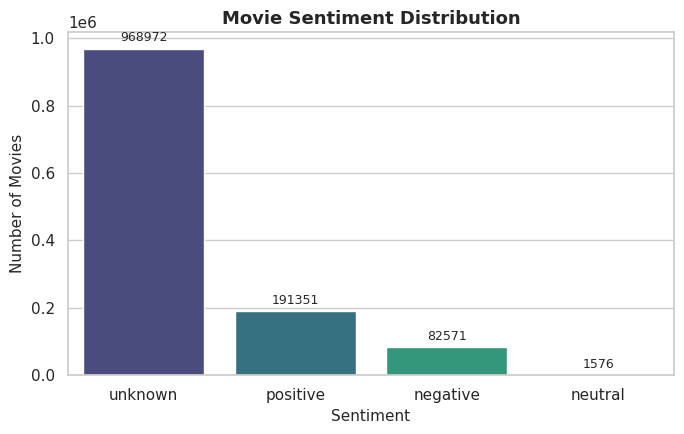

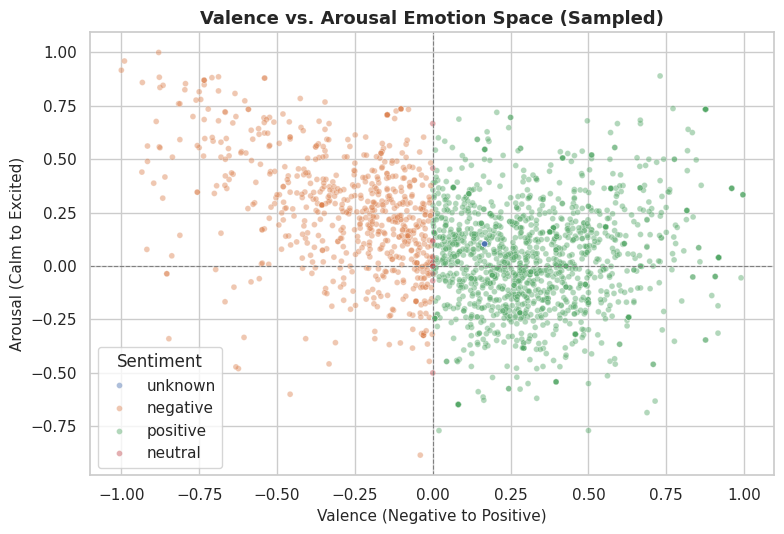

In [8]:
# --- Graph 1: Sentiment Distribution (Bar Chart) ---
plt.figure(figsize=(7, 4.5))
sentiment_counts = df["sentiment"].value_counts()
ax1 = sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
    hue=sentiment_counts.index,
    palette="viridis",
    legend=False
)
plt.title("Movie Sentiment Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Sentiment", fontsize=11)
plt.ylabel("Number of Movies", fontsize=11)

for container in ax1.containers:
    ax1.bar_label(container, fmt="%d", padding=3, fontsize=9)

plt.tight_layout()
plt.show()


# --- Graph 2: Valence vs. Arousal (Scatter Plot) ---
plot_sample = df.dropna(subset=["valence", "arousal", "sentiment"]).sample(
    n=min(10000, len(df)), random_state=42
)

plt.figure(figsize=(8, 5.5))
sns.scatterplot(
    data=plot_sample,
    x="valence",
    y="arousal",
    hue="sentiment",
    alpha=0.45,
    s=18
)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Valence vs. Arousal Emotion Space (Sampled)", fontsize=13, fontweight="bold")
plt.xlabel("Valence (Negative to Positive)", fontsize=11)
plt.ylabel("Arousal (Calm to Excited)", fontsize=11)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

**Marking Criteria** CLO-I \
For marks 30, the marking will be done according to the following criteria.

| Component | Marks |
| :--- | :---: |
| Report | 10 |
| Data Cleaning | 5 |
| Data Preprocessing | 10 |
| Feature Engineering | 5 |
